In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Read the raw BGL dataset from a CSV file
df_diatrend = pd.read_csv('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Datasets/2025-12-05/Preprocessed/diatrend/cgm_temp_diatrend_raw.csv')
df_diatrend.head()

,Patient_ID,Timestamp,GlucoseValue
0,1,2015-12-01 21:01:07,160.0
1,1,2015-12-01 21:06:07,161.0
2,1,2015-12-01 21:11:08,165.0
3,1,2015-12-01 21:16:08,162.0
4,1,2015-12-01 21:21:07,163.0


In [4]:
df_diatrend.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7680740 entries, 0 to 7680739
Data columns (total 3 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Patient_ID    int64  
 1   Timestamp     object 
 2   GlucoseValue  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 175.8+ MB


In [5]:
df_diatrend['GlucoseValue'].mean()

186.3037546636236

In [6]:
df_diatrend['GlucoseValue'].std()

74.17743198770296

 --- DETAILED STATISTICS ---  
Metric               |      Value
-----------------------------------
Mean                 |     186.30
Std Deviation        |      74.18
-----------------------------------
Min Value            |      38.97
Lower Fence (Limit)  |     -21.50
Q1 (Box Start)       |     130.00
Median (Line)        |     175.00
Q3 (Box End)         |     231.00
Upper Fence (Limit)  |     382.50
Max Value            |     401.00
IQR                  |     101.00
-----------------------------------
Percentile Method (80% of data)
Logic: Between 10th and 90th Percentile
Range: [100.00  to  288.00]
Interpretation: 'The vast majority (80%) of readings fall between these values.'
----------------------------------------


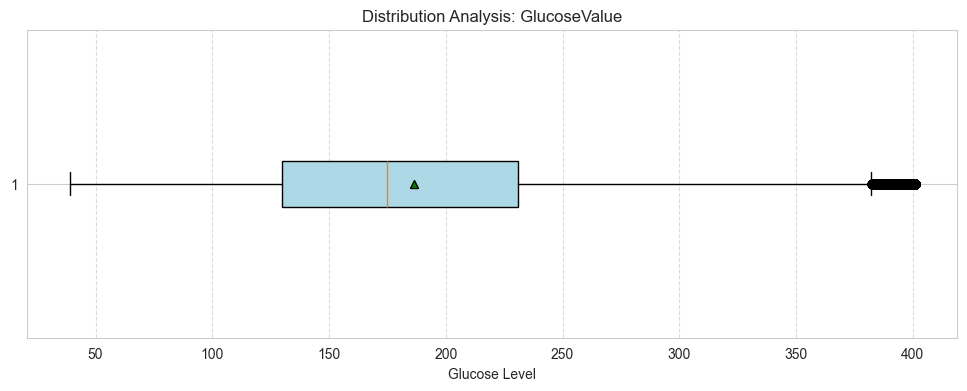

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Prepare Data
data = df_diatrend['GlucoseValue'].dropna()

# 2. Calculate Statistics
desc = data.describe()
mean_val = desc['mean']
std_val = desc['std']
q1 = desc['25%']
median = desc['50%']
q3 = desc['75%']
iqr = q3 - q1

# Calculate theoretical whisker limits (Tukey's fences) for outlier detection
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# --- THE REALISTIC "MAJORITY" (80% via Percentiles) ---
# Best if your data is skewed or has outliers (like your glucose data)
# We take the 10th percentile and the 90th percentile. 
# Everything in between is the middle 80%.
p10 = data.quantile(0.10)
p90 = data.quantile(0.90)

# 3. Print Detailed Report
print(f"{'--- DETAILED STATISTICS ---':^30}")
print(f"{'Metric':<20} | {'Value':>10}")
print("-" * 35)
print(f"{'Mean':<20} | {mean_val:10.2f}")
print(f"{'Std Deviation':<20} | {std_val:10.2f}")
print("-" * 35)
print(f"{'Min Value':<20} | {desc['min']:10.2f}")
print(f"{'Lower Fence (Limit)':<20} | {lower_fence:10.2f}")
print(f"{'Q1 (Box Start)':<20} | {q1:10.2f}")
print(f"{'Median (Line)':<20} | {median:10.2f}")
print(f"{'Q3 (Box End)':<20} | {q3:10.2f}")
print(f"{'Upper Fence (Limit)':<20} | {upper_fence:10.2f}")
print(f"{'Max Value':<20} | {desc['max']:10.2f}")
print(f"{'IQR':<20} | {iqr:10.2f}")
print("-" * 35)

print("Percentile Method (80% of data)")
print(f"Logic: Between 10th and 90th Percentile")
print(f"Range: [{p10:.2f}  to  {p90:.2f}]")
print("Interpretation: 'The vast majority (80%) of readings fall between these values.'")
print("-" * 40)

# 4. Plot
plt.figure(figsize=(12, 4))
# 'showmeans' adds a green triangle for the mean
# 'vert=False' makes it horizontal for easier reading
plt.boxplot(data, vert=False, patch_artist=True, showmeans=True, 
            boxprops=dict(facecolor='#add8e6', color='black'),
            meanprops=dict(marker='^', markeredgecolor='black', markerfacecolor='green'))

plt.title('Distribution Analysis: GlucoseValue')
plt.xlabel('Glucose Level')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

  --- NORMALITY RANGES (GAUSSIAN) ---   
Mean (mu): 186.30
Std Dev (sigma): 74.18
----------------------------------------
95% Confidence (2 sigma):  [37.95  to  334.66]
99.7% Confidence (3 sigma):[-36.23  to  408.84]
----------------------------------------
Note: The theoretical lower limit is negative, which might not be physically possible for Glucose.


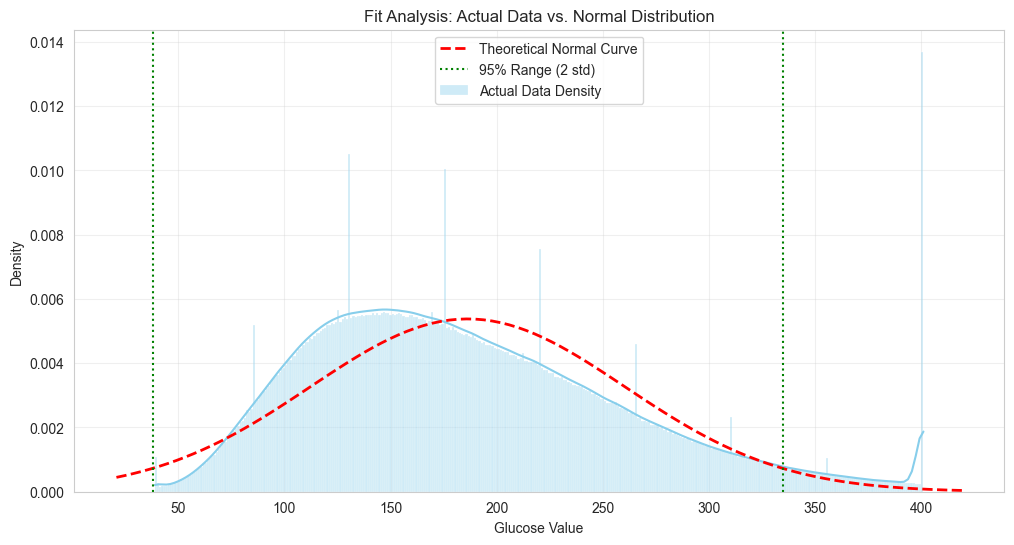

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Prepare Data
data = df_diatrend['GlucoseValue'].dropna()

# 2. Calculate Gaussian Parameters (Mean and Std Dev)
mu, std = norm.fit(data)

# 3. Calculate "Normality" Ranges (The Empirical Rule)
# 95% of data falls within 2 standard deviations (Typical Range)
limit_95_low = mu - (2 * std)
limit_95_high = mu + (2 * std)

# 99.7% of data falls within 3 standard deviations (Strict Limit)
limit_99_low = mu - (3 * std)
limit_99_high = mu + (3 * std)

# 4. Print Exact Values
print(f"{'--- NORMALITY RANGES (GAUSSIAN) ---':^40}")
print(f"Mean (mu): {mu:.2f}")
print(f"Std Dev (sigma): {std:.2f}")
print("-" * 40)
print(f"95% Confidence (2 sigma):  [{limit_95_low:.2f}  to  {limit_95_high:.2f}]")
print(f"99.7% Confidence (3 sigma):[{limit_99_low:.2f}  to  {limit_99_high:.2f}]")
print("-" * 40)
if limit_99_low < 0:
    print("Note: The theoretical lower limit is negative, which might not be physically possible for Glucose.")

# 5. Visualization: Actual vs Theoretical
plt.figure(figsize=(12, 6))

# A. Histogram & KDE (Kernel Density Estimate) -> The "Real" Data shape
# stat='density' normalizes the histogram so it matches the curve
sns.histplot(data, kde=True, stat="density", color="skyblue", label="Actual Data Density", alpha=0.4)

# B. Theoretical Normal Distribution -> The "Perfect" shape
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std) # Probability Density Function
plt.plot(x, p, 'r--', linewidth=2, label="Theoretical Normal Curve")

# C. Add Vertical Lines for the 95% Range
plt.axvline(limit_95_low, color='green', linestyle=':', label='95% Range (2 std)')
plt.axvline(limit_95_high, color='green', linestyle=':')

plt.title('Fit Analysis: Actual Data vs. Normal Distribution')
plt.xlabel('Glucose Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [12]:
def calc_ranges(df_measurements:pd.DataFrame) -> []:
    too_low_glucose_serie = df_measurements[df_measurements['GlucoseValue'] < 54]['GlucoseValue'].shape[0] # glucose < 54
    low_glucose_serie = df_measurements[(df_measurements['GlucoseValue'] >= 54) & (df_measurements['GlucoseValue'] <= 69)]['GlucoseValue'].shape[0] # 54 <= glucose <= 69
    ok_glucose_serie = df_measurements[(df_measurements['GlucoseValue'] >= 70) & (df_measurements['GlucoseValue'] <= 180)]['GlucoseValue'].shape[0] # 70 <= glucose <= 180
    high_glucose_serie = df_measurements[(df_measurements['GlucoseValue'] >= 181) & (df_measurements['GlucoseValue'] <= 250)]['GlucoseValue'].shape[0] # 181 <= glucose < 250
    too_high_glucose_serie = df_measurements[df_measurements['GlucoseValue'] > 250]['GlucoseValue'].shape[0] # glucose >= 250
    
    return [too_low_glucose_serie, low_glucose_serie, ok_glucose_serie, high_glucose_serie, too_high_glucose_serie]

arr = calc_ranges(df_diatrend)

In [13]:
arr

[35150, 105548, 3908494, 2193815, 1435054]

In [14]:
# add all values in arr
total = sum(arr)

# calc percentage of each value in arr
percentages = [round((value / total * 100),2) for value in arr]
percentages

[0.46, 1.37, 50.9, 28.57, 18.69]

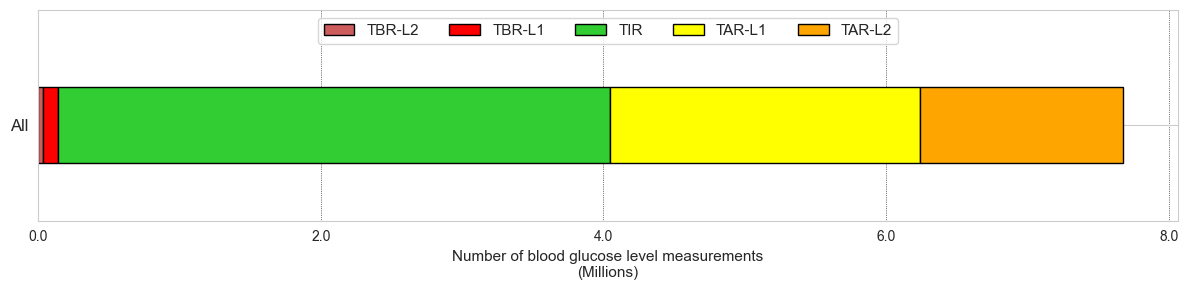

In [15]:
# -- GRAPH ----
total_values = arr 
categories = ['All'] 

# --- CONFIGURACIÓN ---
# Usamos tight_layout=True para que Matplotlib gestione los márgenes automáticamente
fig = plt.figure(figsize=(12, 3), tight_layout=True)
ax = fig.add_subplot(111)

range_labels = ['TBR-L2', 'TBR-L1', 'TIR', 'TAR-L1', 'TAR-L2']
bar_colors = ['indianred', 'red', 'limegreen', 'yellow', 'orange']
y_pos = 0 

# --- DIBUJO ---
left_offset = 0 
for i in range(len(total_values)):
    ax.barh(y_pos, 
            total_values[i], 
            left=left_offset, 
            label=range_labels[i], 
            color=bar_colors[i], 
            height=0.4, 
            edgecolor="black")
    left_offset += total_values[i]

# --- AJUSTES CLAVE PARA LA LEYENDA DENTRO ---

# 1. Ampliamos el límite superior del Eje Y.
# La barra llega hasta y=0.2. Al poner el límite en 1.0, 
# creamos un espacio vacío grande encima de la barra pero DENTRO de la cuadrícula.
ax.set_ylim(-0.5, 1.0) 

# 2. Colocamos la leyenda en la parte superior central de ese espacio.
# loc='upper center' la pone pegada al límite superior (1.0).
ax.legend(loc='upper center', ncol=5, frameon=True, fontsize=11)


# --- RESTO DE FORMATO ---
ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')
ax.set_xlabel('Number of blood glucose level measurements\n(Millions)', fontsize=11)

# Eje Y
ax.set_yticks([y_pos])
ax.set_yticklabels(categories, fontsize=12)

# Eje X (Cálculo dinámico)
total_sum = np.sum(total_values)
max_lim = int(np.ceil(total_sum / 1000000) * 1000000) + 1000000
step = 2000000 if total_sum < 20000000 else 2000000 

x_ticks_values = np.arange(0, max_lim + 1, step)
x_ticks_labels = list(map(str, x_ticks_values/1000000))

ax.xaxis.set_ticks(x_ticks_values)
ax.xaxis.set_ticklabels(x_ticks_labels)
# ax.set_xlim(0, 22000000)

ax.set_ylim(-0.5, 0.6)

# plt.savefig("BGL_ranges_dist.png", 
#             bbox_inches='tight',   # Recorte de bordes (quita el espacio blanco sobrante)
#             pad_inches=0.1,        # Un pequeño margen extra opcional (si quieres que no esté pegado al borde)
#             dpi=300,               # Densidad (300 es estándar para impresión/publicación, 72 para web)
#             format='png')

plt.show()

# Repeat now for T1DiabetesGranada dataset

In [16]:
df_t1granada = pd.read_csv('c:/Users/Ciro/Mi unidad (e.crleon@go.ugr.es)/_UGR_in_go_2024-05-30/T1DiabetesGranada/T1DiabetesGranada/Glucose_measurements.csv')
df_t1granada.head()

,Patient_ID,Measurement_date,Measurement_time,Measurement
0,LIB193263,2020-06-09,19:08:00,99
1,LIB193263,2020-06-09,19:23:00,92
2,LIB193263,2020-06-09,19:38:00,86
3,LIB193263,2020-06-09,19:53:00,85
4,LIB193263,2020-06-09,20:08:00,85


In [17]:
df_t1granada.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22671708 entries, 0 to 22671707
Data columns (total 4 columns):
 #   Column            Dtype 
---  ------            ----- 
 0   Patient_ID        object
 1   Measurement_date  object
 2   Measurement_time  object
 3   Measurement       int64 
dtypes: int64(1), object(3)
memory usage: 691.9+ MB


In [18]:
df_t1granada['Measurement'].mean()

164.78373265922443

In [19]:
df_t1granada['Measurement'].std()

71.57473580853565

 --- DETAILED STATISTICS ---  
Metric               |      Value
-----------------------------------
Mean                 |     164.78
Std Deviation        |      71.57
-----------------------------------
Min Value            |      40.00
Lower Fence (Limit)  |     -29.00
Q1 (Box Start)       |     112.00
Median (Line)        |     153.00
Q3 (Box End)         |     206.00
Upper Fence (Limit)  |     347.00
Max Value            |     500.00
IQR                  |      94.00
-----------------------------------
Percentile Method (80% of data)
Logic: Between 10th and 90th Percentile
Range: [84.00  to  260.00]
Interpretation: 'The vast majority (80%) of readings fall between these values.'
----------------------------------------


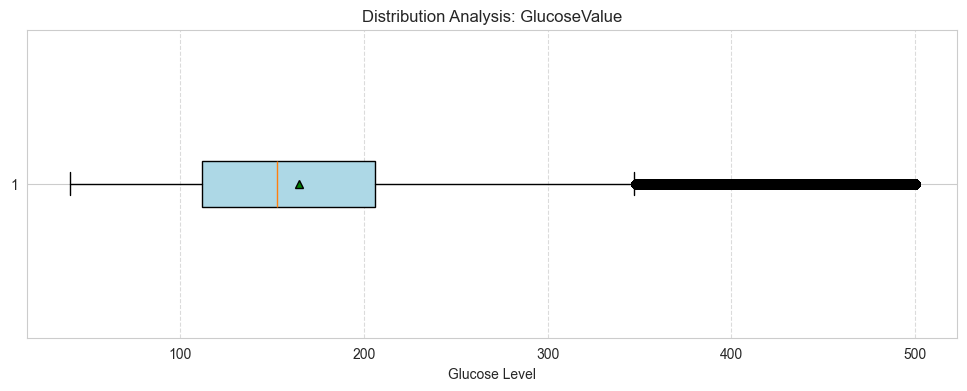

In [22]:
# Box plot and detailed statistics
import matplotlib.pyplot as plt
import numpy as np
# 1. Prepare Data
data = df_t1granada['Measurement'].dropna()


# 2. Calculate Statistics
desc = data.describe()
mean_val = desc['mean']
std_val = desc['std']
q1 = desc['25%']
median = desc['50%']
q3 = desc['75%']
iqr = q3 - q1

# Calculate theoretical whisker limits (Tukey's fences) for outlier detection
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# --- THE REALISTIC "MAJORITY" (80% via Percentiles) ---
# Best if your data is skewed or has outliers (like your glucose data)
# We take the 10th percentile and the 90th percentile. 
# Everything in between is the middle 80%.
p10 = data.quantile(0.10)
p90 = data.quantile(0.90)

# 3. Print Detailed Report
print(f"{'--- DETAILED STATISTICS ---':^30}")
print(f"{'Metric':<20} | {'Value':>10}")
print("-" * 35)
print(f"{'Mean':<20} | {mean_val:10.2f}")
print(f"{'Std Deviation':<20} | {std_val:10.2f}")
print("-" * 35)
print(f"{'Min Value':<20} | {desc['min']:10.2f}")
print(f"{'Lower Fence (Limit)':<20} | {lower_fence:10.2f}")
print(f"{'Q1 (Box Start)':<20} | {q1:10.2f}")
print(f"{'Median (Line)':<20} | {median:10.2f}")
print(f"{'Q3 (Box End)':<20} | {q3:10.2f}")
print(f"{'Upper Fence (Limit)':<20} | {upper_fence:10.2f}")
print(f"{'Max Value':<20} | {desc['max']:10.2f}")
print(f"{'IQR':<20} | {iqr:10.2f}")
print("-" * 35)

print("Percentile Method (80% of data)")
print(f"Logic: Between 10th and 90th Percentile")
print(f"Range: [{p10:.2f}  to  {p90:.2f}]")
print("Interpretation: 'The vast majority (80%) of readings fall between these values.'")
print("-" * 40)

# 4. Plot
plt.figure(figsize=(12, 4))
# 'showmeans' adds a green triangle for the mean
# 'vert=False' makes it horizontal for easier reading
plt.boxplot(data, vert=False, patch_artist=True, showmeans=True, 
            boxprops=dict(facecolor='#add8e6', color='black'),
            meanprops=dict(marker='^', markeredgecolor='black', markerfacecolor='green'))

plt.title('Distribution Analysis: GlucoseValue')
plt.xlabel('Glucose Level')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


  --- NORMALITY RANGES (GAUSSIAN) ---   
Mean (mu): 164.78
Std Dev (sigma): 71.57
----------------------------------------
95% Confidence (2 sigma):  [21.63  to  307.93]
99.7% Confidence (3 sigma):[-49.94  to  379.51]
----------------------------------------
Note: The theoretical lower limit is negative, which might not be physically possible for Glucose.


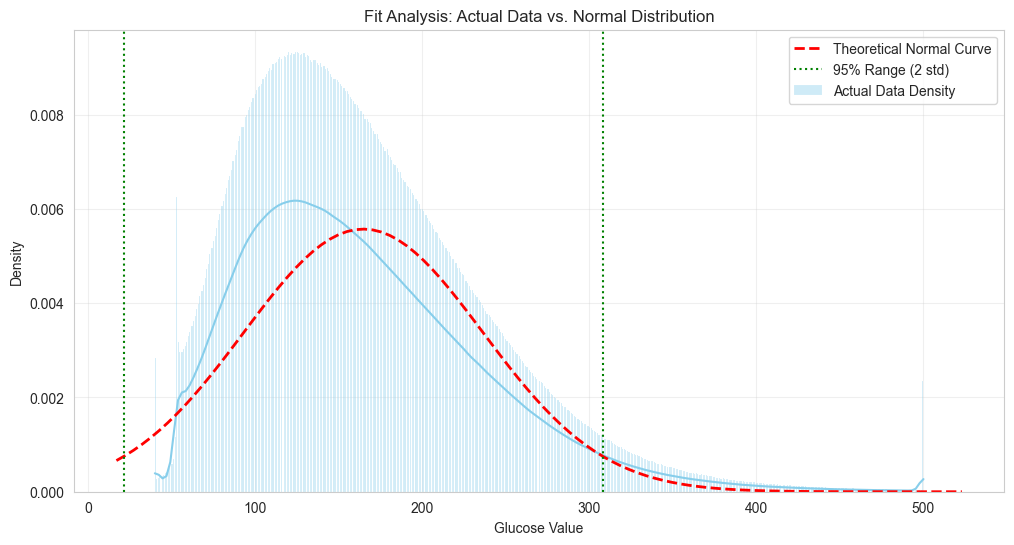

In [23]:
# Normality analysis
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
# 1. Prepare Data
data = df_t1granada['Measurement'].dropna()
# 2. Calculate Gaussian Parameters (Mean and Std Dev)
mu, std = norm.fit(data)
# 3. Calculate "Normality" Ranges (The Empirical Rule)
# 95% of data falls within 2 standard deviations (Typical Range)
limit_95_low = mu - (2 * std)
limit_95_high = mu + (2 * std)
# 99.7% of data falls within 3 standard deviations (Strict Limit)
limit_99_low = mu - (3 * std)
limit_99_high = mu + (3 * std)
# 4. Print Exact Values
print(f"{'--- NORMALITY RANGES (GAUSSIAN) ---':^40}")
print(f"Mean (mu): {mu:.2f}")
print(f"Std Dev (sigma): {std:.2f}")
print("-" * 40)
print(f"95% Confidence (2 sigma):  [{limit_95_low:.2f}  to  {limit_95_high:.2f}]")
print(f"99.7% Confidence (3 sigma):[{limit_99_low:.2f}  to  {limit_99_high:.2f}]")
print("-" * 40)
if limit_99_low < 0:
    print("Note: The theoretical lower limit is negative, which might not be physically possible for Glucose.")

# 5. Visualization: Actual vs Theoretical
plt.figure(figsize=(12, 6))
# A. Histogram & KDE (Kernel Density Estimate) -> The "Real" Data shape
# stat='density' normalizes the histogram so it matches the curve
sns.histplot(data, kde=True, stat="density", color="skyblue", label="Actual Data Density", alpha=0.4)
# B. Theoretical Normal Distribution -> The "Perfect" shape
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std) # Probability Density Function
plt.plot(x, p, 'r--', linewidth=2, label="Theoretical Normal Curve")
# C. Add Vertical Lines for the 95% Range
plt.axvline(limit_95_low, color='green', linestyle=':', label='95% Range (2 std)')
plt.axvline(limit_95_high, color='green', linestyle=':')
plt.title('Fit Analysis: Actual Data vs. Normal Distribution')
plt.xlabel('Glucose Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



In [24]:
# Range calculation
def calc_ranges_t1granada(df_measurements:pd.DataFrame) -> []:
    too_low_glucose_serie = df_measurements[df_measurements['Measurement'] < 54]['Measurement'].shape[0] # glucose < 54
    low_glucose_serie = df_measurements[(df_measurements['Measurement'] >= 54) & (df_measurements['Measurement'] <= 69)]['Measurement'].shape[0] # 54 <= glucose <= 69
    ok_glucose_serie = df_measurements[(df_measurements['Measurement'] >= 70) & (df_measurements['Measurement'] <= 180)]['Measurement'].shape[0] # 70 <= glucose <= 180
    high_glucose_serie = df_measurements[(df_measurements['Measurement'] >= 181) & (df_measurements['Measurement'] <= 250)]['Measurement'].shape[0] # 181 <= glucose < 250
    too_high_glucose_serie = df_measurements[df_measurements['Measurement'] > 250]['Measurement'].shape[0] # glucose >= 250
    
    return [too_low_glucose_serie, low_glucose_serie, ok_glucose_serie, high_glucose_serie, too_high_glucose_serie]

arr_t1granada = calc_ranges_t1granada(df_t1granada)
arr_t1granada

[223505, 852915, 13506999, 5392360, 2695929]

In [25]:
# add all values in arr
total_t1granada = sum(arr_t1granada)
# calc percentage of each value in arr
percentages_t1granada = [round((value / total_t1granada * 100),2) for value in arr_t1granada]
percentages_t1granada

[0.99, 3.76, 59.58, 23.78, 11.89]

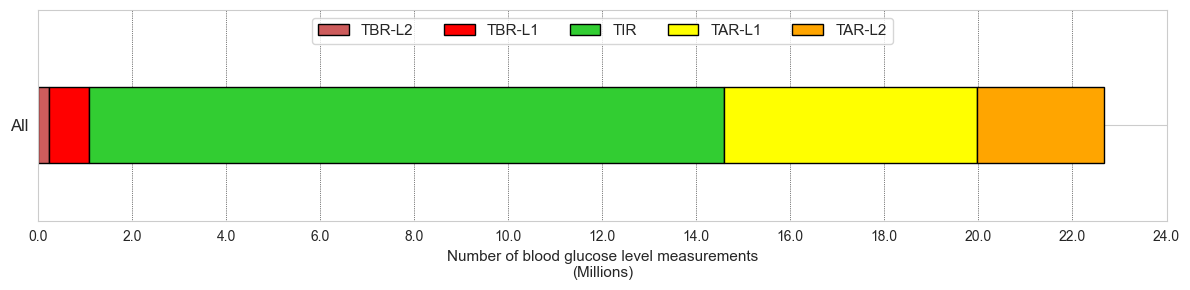

In [26]:
# -- GRAPH ----
total_values = arr_t1granada 
categories = ['All'] 

# --- CONFIGURACIÓN ---
# Usamos tight_layout=True para que Matplotlib gestione los márgenes automáticamente
fig = plt.figure(figsize=(12, 3), tight_layout=True)
ax = fig.add_subplot(111)

range_labels = ['TBR-L2', 'TBR-L1', 'TIR', 'TAR-L1', 'TAR-L2']
bar_colors = ['indianred', 'red', 'limegreen', 'yellow', 'orange']
y_pos = 0 

# --- DIBUJO ---
left_offset = 0 
for i in range(len(total_values)):
    ax.barh(y_pos, 
            total_values[i], 
            left=left_offset, 
            label=range_labels[i], 
            color=bar_colors[i], 
            height=0.4, 
            edgecolor="black")
    left_offset += total_values[i]

# --- AJUSTES CLAVE PARA LA LEYENDA DENTRO ---

# 1. Ampliamos el límite superior del Eje Y.
# La barra llega hasta y=0.2. Al poner el límite en 1.0, 
# creamos un espacio vacío grande encima de la barra pero DENTRO de la cuadrícula.
ax.set_ylim(-0.5, 1.0) 

# 2. Colocamos la leyenda en la parte superior central de ese espacio.
# loc='upper center' la pone pegada al límite superior (1.0).
ax.legend(loc='upper center', ncol=5, frameon=True, fontsize=11)


# --- RESTO DE FORMATO ---
ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')
ax.set_xlabel('Number of blood glucose level measurements\n(Millions)', fontsize=11)

# Eje Y
ax.set_yticks([y_pos])
ax.set_yticklabels(categories, fontsize=12)

# Eje X (Cálculo dinámico)
total_sum = np.sum(total_values)
max_lim = int(np.ceil(total_sum / 1000000) * 1000000) + 1000000
step = 2000000 if total_sum < 20000000 else 2000000 

x_ticks_values = np.arange(0, max_lim + 1, step)
x_ticks_labels = list(map(str, x_ticks_values/1000000))

ax.xaxis.set_ticks(x_ticks_values)
ax.xaxis.set_ticklabels(x_ticks_labels)
# ax.set_xlim(0, 22000000)

ax.set_ylim(-0.5, 0.6)

# plt.savefig("BGL_ranges_dist.png", 
#             bbox_inches='tight',   # Recorte de bordes (quita el espacio blanco sobrante)
#             pad_inches=0.1,        # Un pequeño margen extra opcional (si quieres que no esté pegado al borde)
#             dpi=300,               # Densidad (300 es estándar para impresión/publicación, 72 para web)
#             format='png')

plt.show()

# repeat now for Replace/bg dataset

In [27]:
df_replacebg = pd.read_csv('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Datasets/2025-12-05/Preprocessed/replace/cgm_temp_replace_raw.csv')
df_replacebg.head()

,Patient_ID,Timestamp,GlucoseValue
0,2,2000-03-08 00:04:50,166.0
1,2,2000-03-08 00:09:50,169.0
2,2,2000-03-08 00:14:50,161.0
3,2,2000-03-08 00:19:50,158.0
4,2,2000-03-08 00:24:50,157.0


In [28]:
df_replacebg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10398870 entries, 0 to 10398869
Data columns (total 3 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Patient_ID    int64  
 1   Timestamp     object 
 2   GlucoseValue  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 238.0+ MB


 --- DETAILED STATISTICS ---  
Metric               |      Value
-----------------------------------
Mean                 |     159.89
Std Deviation        |      64.12
-----------------------------------
Min Value            |      39.00
Lower Fence (Limit)  |     -15.50
Q1 (Box Start)       |     112.00
Median (Line)        |     150.00
Q3 (Box End)         |     197.00
Upper Fence (Limit)  |     324.50
Max Value            |     401.00
IQR                  |      85.00
-----------------------------------
Percentile Method (80% of data)
Logic: Between 10th and 90th Percentile
Range: [86.00  to  247.00]
Interpretation: 'The vast majority (80%) of readings fall between these values.'
----------------------------------------


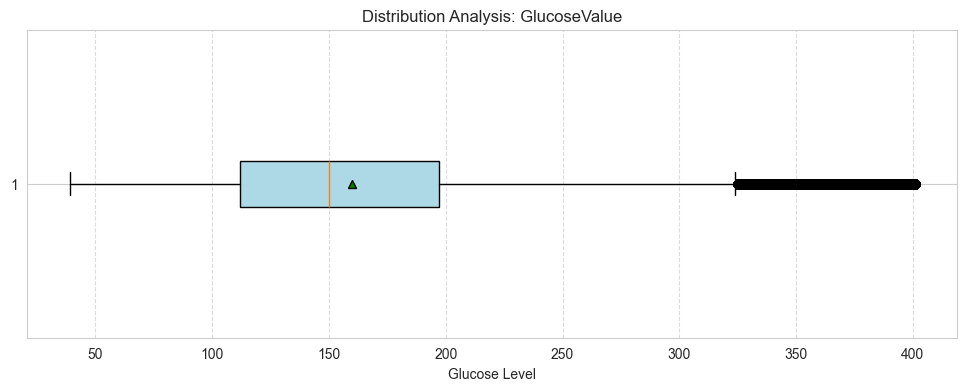

In [30]:
# box plot and detailed statistics
import matplotlib.pyplot as plt
import numpy as np
# 1. Prepare Data
data = df_replacebg['GlucoseValue'].dropna()

# 2. Calculate Statistics
desc = data.describe()
mean_val = desc['mean']
std_val = desc['std']
q1 = desc['25%']
median = desc['50%']
q3 = desc['75%']
iqr = q3 - q1

# Calculate theoretical whisker limits (Tukey's fences) for outlier detection
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# --- THE REALISTIC "MAJORITY" (80% via Percentiles) ---
# Best if your data is skewed or has outliers (like your glucose data)
# We take the 10th percentile and the 90th percentile. 
# Everything in between is the middle 80%.
p10 = data.quantile(0.10)
p90 = data.quantile(0.90)

# 3. Print Detailed Report
print(f"{'--- DETAILED STATISTICS ---':^30}")
print(f"{'Metric':<20} | {'Value':>10}")
print("-" * 35)
print(f"{'Mean':<20} | {mean_val:10.2f}")
print(f"{'Std Deviation':<20} | {std_val:10.2f}")
print("-" * 35)
print(f"{'Min Value':<20} | {desc['min']:10.2f}")
print(f"{'Lower Fence (Limit)':<20} | {lower_fence:10.2f}")
print(f"{'Q1 (Box Start)':<20} | {q1:10.2f}")
print(f"{'Median (Line)':<20} | {median:10.2f}")
print(f"{'Q3 (Box End)':<20} | {q3:10.2f}")
print(f"{'Upper Fence (Limit)':<20} | {upper_fence:10.2f}")
print(f"{'Max Value':<20} | {desc['max']:10.2f}")
print(f"{'IQR':<20} | {iqr:10.2f}")
print("-" * 35)

print("Percentile Method (80% of data)")
print(f"Logic: Between 10th and 90th Percentile")
print(f"Range: [{p10:.2f}  to  {p90:.2f}]")
print("Interpretation: 'The vast majority (80%) of readings fall between these values.'")
print("-" * 40)

# 4. Plot
plt.figure(figsize=(12, 4))
# 'showmeans' adds a green triangle for the mean
# 'vert=False' makes it horizontal for easier reading
plt.boxplot(data, vert=False, patch_artist=True, showmeans=True, 
            boxprops=dict(facecolor='#add8e6', color='black'),
            meanprops=dict(marker='^', markeredgecolor='black', markerfacecolor='green'))

plt.title('Distribution Analysis: GlucoseValue')
plt.xlabel('Glucose Level')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


  --- NORMALITY RANGES (GAUSSIAN) ---   
Mean (mu): 159.89
Std Dev (sigma): 64.12
----------------------------------------
95% Confidence (2 sigma):  [31.65  to  288.13]
99.7% Confidence (3 sigma):[-32.47  to  352.25]
----------------------------------------
Note: The theoretical lower limit is negative, which might not be physically possible for Glucose.


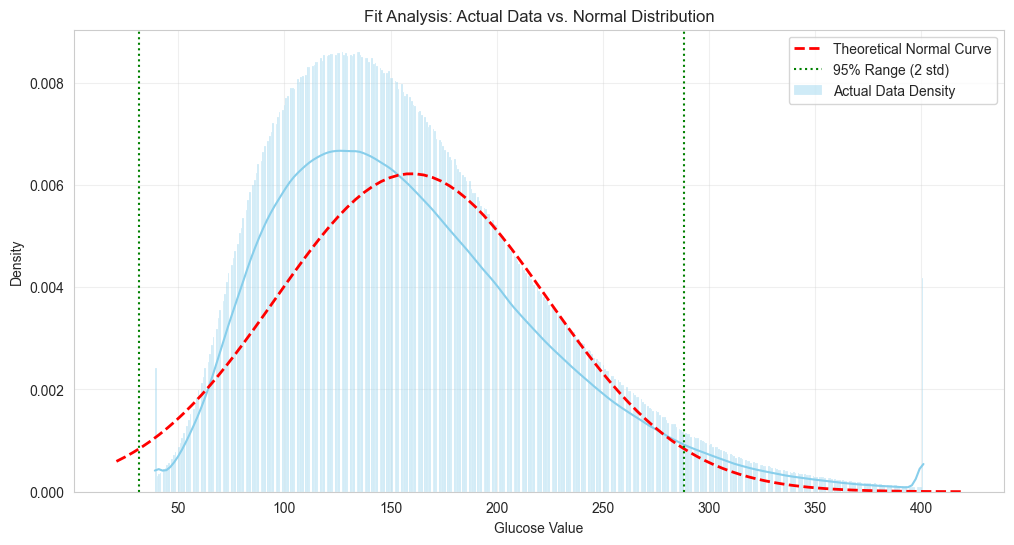

In [31]:
# 1. Prepare Data
data = df_replacebg['GlucoseValue'].dropna() 

# 2. Calculate Gaussian Parameters (Mean and Std Dev)
mu, std = norm.fit(data)

# 3. Calculate "Normality" Ranges (The Empirical Rule)
# 95% of data falls within 2 standard deviations (Typical Range)
limit_95_low = mu - (2 * std)
limit_95_high = mu + (2 * std)

# 99.7% of data falls within 3 standard deviations (Strict Limit)
limit_99_low = mu - (3 * std)
limit_99_high = mu + (3 * std)

# 4. Print Exact Values
print(f"{'--- NORMALITY RANGES (GAUSSIAN) ---':^40}")
print(f"Mean (mu): {mu:.2f}")
print(f"Std Dev (sigma): {std:.2f}")
print("-" * 40)
print(f"95% Confidence (2 sigma):  [{limit_95_low:.2f}  to  {limit_95_high:.2f}]")
print(f"99.7% Confidence (3 sigma):[{limit_99_low:.2f}  to  {limit_99_high:.2f}]")
print("-" * 40)
if limit_99_low < 0:
    print("Note: The theoretical lower limit is negative, which might not be physically possible for Glucose.")

# 5. Visualization: Actual vs Theoretical
plt.figure(figsize=(12, 6))

# A. Histogram & KDE (Kernel Density Estimate) -> The "Real" Data shape
# stat='density' normalizes the histogram so it matches the curve
sns.histplot(data, kde=True, stat="density", color="skyblue", label="Actual Data Density", alpha=0.4)

# B. Theoretical Normal Distribution -> The "Perfect" shape
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std) # Probability Density Function
plt.plot(x, p, 'r--', linewidth=2, label="Theoretical Normal Curve")

# C. Add Vertical Lines for the 95% Range
plt.axvline(limit_95_low, color='green', linestyle=':', label='95% Range (2 std)')
plt.axvline(limit_95_high, color='green', linestyle=':')

plt.title('Fit Analysis: Actual Data vs. Normal Distribution')
plt.xlabel('Glucose Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [32]:
# Range calculation
def calc_ranges_replacebg(df_measurements:pd.DataFrame) -> []:
    too_low_glucose_serie = df_measurements[df_measurements['GlucoseValue'] < 54]['GlucoseValue'].shape[0] # glucose < 54
    low_glucose_serie = df_measurements[(df_measurements['GlucoseValue'] >= 54) & (df_measurements['GlucoseValue'] <= 69)]['GlucoseValue'].shape[0] # 54 <= glucose <= 69
    ok_glucose_serie = df_measurements[(df_measurements['GlucoseValue'] >= 70) & (df_measurements['GlucoseValue'] <= 180)]['GlucoseValue'].shape[0] # 70 <= glucose <= 180
    high_glucose_serie = df_measurements[(df_measurements['GlucoseValue'] >= 181) & (df_measurements['GlucoseValue'] <= 250)]['GlucoseValue'].shape[0] # 181 <= glucose < 250
    too_high_glucose_serie = df_measurements[df_measurements['GlucoseValue'] > 250]['GlucoseValue'].shape[0] # glucose >= 250
    
    return [too_low_glucose_serie, low_glucose_serie, ok_glucose_serie, high_glucose_serie, too_high_glucose_serie]

arr_replacebg = calc_ranges_replacebg(df_replacebg)
arr_replacebg

[94119, 290767, 6615399, 2429737, 968848]

In [33]:
# add all values in arr
total_replacebg = sum(arr_replacebg)

# calc percentage of each value in arr
percentages_replacebg = [round((value / total_replacebg * 100),2) for value in arr_replacebg]
percentages_replacebg

[0.91, 2.8, 63.62, 23.37, 9.32]

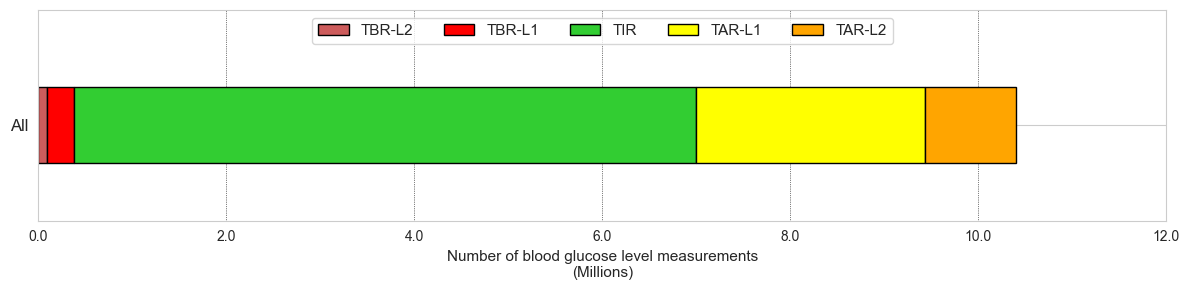

In [34]:
# -- GRAPH ----
total_values = arr_replacebg
categories = ['All'] 

# --- CONFIGURACIÓN ---
# Usamos tight_layout=True para que Matplotlib gestione los márgenes automáticamente
fig = plt.figure(figsize=(12, 3), tight_layout=True)
ax = fig.add_subplot(111)

range_labels = ['TBR-L2', 'TBR-L1', 'TIR', 'TAR-L1', 'TAR-L2']
bar_colors = ['indianred', 'red', 'limegreen', 'yellow', 'orange']
y_pos = 0 

# --- DIBUJO ---
left_offset = 0 
for i in range(len(total_values)):
    ax.barh(y_pos, 
            total_values[i], 
            left=left_offset, 
            label=range_labels[i], 
            color=bar_colors[i], 
            height=0.4, 
            edgecolor="black")
    left_offset += total_values[i]

# --- AJUSTES CLAVE PARA LA LEYENDA DENTRO ---

# 1. Ampliamos el límite superior del Eje Y.
# La barra llega hasta y=0.2. Al poner el límite en 1.0, 
# creamos un espacio vacío grande encima de la barra pero DENTRO de la cuadrícula.
ax.set_ylim(-0.5, 1.0) 

# 2. Colocamos la leyenda en la parte superior central de ese espacio.
# loc='upper center' la pone pegada al límite superior (1.0).
ax.legend(loc='upper center', ncol=5, frameon=True, fontsize=11)


# --- RESTO DE FORMATO ---
ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')
ax.set_xlabel('Number of blood glucose level measurements\n(Millions)', fontsize=11)

# Eje Y
ax.set_yticks([y_pos])
ax.set_yticklabels(categories, fontsize=12)

# Eje X (Cálculo dinámico)
total_sum = np.sum(total_values)
max_lim = int(np.ceil(total_sum / 1000000) * 1000000) + 1000000
step = 2000000 if total_sum < 20000000 else 2000000 

x_ticks_values = np.arange(0, max_lim + 1, step)
x_ticks_labels = list(map(str, x_ticks_values/1000000))

ax.xaxis.set_ticks(x_ticks_values)
ax.xaxis.set_ticklabels(x_ticks_labels)
# ax.set_xlim(0, 22000000)

ax.set_ylim(-0.5, 0.6)

# plt.savefig("BGL_ranges_dist.png", 
#             bbox_inches='tight',   # Recorte de bordes (quita el espacio blanco sobrante)
#             pad_inches=0.1,        # Un pequeño margen extra opcional (si quieres que no esté pegado al borde)
#             dpi=300,               # Densidad (300 es estándar para impresión/publicación, 72 para web)
#             format='png')

plt.show()